In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter

## Теоретические основы

А. Рекуррентные нейронные сети применяются в основном для анализва временныз последовательностей. Так как используют предыдущие значения.\
Это подойдет для анализа текста, аудио, временных рядов.

В. Примеры формулировки задач:
- «один ко многим» (Р: например, для генерации описания изображений, когда на вход подаются карты признаков изображения, а на выходе получаем его описание (текст), генерация музыки по настроению, подается один вектор (например, жанр или эмоция), на выходе формируется последовательность музыкальных нот)
- «многие ко многим» (Р: например, для перевода текстов, разметка частей речи (последовательность слов на входе, на выходе — последовательность тегов (существительное, глагол) той же длины))
- «многие к одному» (Р: например, для анализа эмоциональной окраски текста (на входе текст, на выходе категории: положительный, нейтральный, отрицательный), прогнозирование отказа двигателя, подается последовательность показаний датчиков за неделю, на выходе — бинарный прогноз)

С. 

D. 

### Подготовка данных

In [26]:
dataset = pd.read_csv("data/baby_names.csv", sep=';')

In [27]:
dataset

,latin,cyrillic,gender
0,John,Джон,boy
1,William,Уильям,boy
2,James,Джеймс,boy
3,Charles,Чарльз,boy
4,George,Джордж,boy
...,...,...,...
6775,Laylah,Лейла,girl
6776,Carleigh,Карли,girl
6777,Kenley,Кенли,girl
6778,Sloane,Слоан,girl


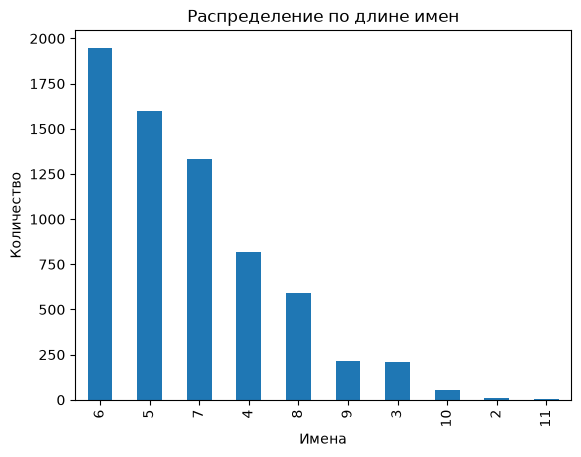

In [28]:
df_temp = dataset['latin'].str.len()
df_temp.value_counts().plot(kind='bar')
plt.title('Распределение по длине имен')
plt.xlabel('Имена')
plt.ylabel('Количество')
plt.show()

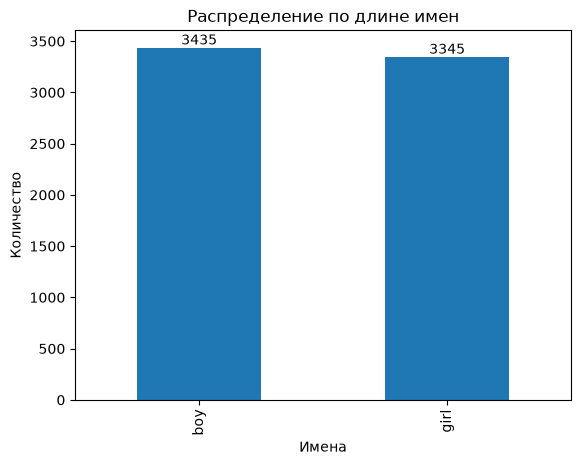

In [29]:
ax = dataset['gender'].value_counts().plot(kind='bar')
ax.bar_label(ax.containers[0])
plt.title('Распределение по длине имен')
plt.xlabel('Имена')
plt.ylabel('Количество')
plt.show()

In [30]:
name_letters = Counter(''.join(dataset['latin'].dropna()))
name_letters.most_common(10)

[('a', 4969),
 ('e', 4653),
 ('n', 3351),
 ('i', 3146),
 ('l', 2775),
 ('r', 2745),
 ('o', 1934),
 ('t', 1419),
 ('s', 1269),
 ('y', 1202)]

## Подготовка данных

In [31]:
# кодирую пол
gender_name_dict = {'boy': 0, 'girl': 1}
dataset['gender'] = dataset['gender'].map(gender_name_dict)

In [32]:
# преобразую все строки к нижнему регистру
dataset['latin'] = dataset['latin'].str.lower()
dataset['cyrillic'] = dataset['cyrillic'].str.lower()

In [33]:
# привожу все к 1 длине и добавляю префикс и постфикс
max_len_latin = 11 + len('<SOS>') + len('<EOS>')

dataset['latin'] = dataset['latin'].map(lambda x: f'<SOS>{x}<EOS>'.ljust(max_len_latin))

In [34]:
dataset

,latin,cyrillic,gender
0,<SOS>john<EOS>,джон,0
1,<SOS>william<EOS>,уильям,0
2,<SOS>james<EOS>,джеймс,0
3,<SOS>charles<EOS>,чарльз,0
4,<SOS>george<EOS>,джордж,0
...,...,...,...
6775,<SOS>laylah<EOS>,лейла,1
6776,<SOS>carleigh<EOS>,карли,1
6777,<SOS>kenley<EOS>,кенли,1
6778,<SOS>sloane<EOS>,слоан,1


In [35]:
# смотрю все ли строки преобразовались к нужной длине
dataset['latin'].str.len().value_counts()

latin
21    6780
Name: count, dtype: int64

!git add ml10.ipynb
!git commit -m "Analyst data"
!git push origin develop